# Classification Supervised Learning

Recall that Supervised Learning has a set of predictor variables trying to predict some response variable. In Classification Supervised Learning, the response variable is a categorical variable. This could be a binary category (like Spam vs Not Spam) or a multiclass category (like type of animal). Different classification models are used under different circumstances of the predictor variables and how complex the relationship between predictor variables and response variable is. 

## Decision Tree

Decision trees aim to create a flowchart-like structure that recursively divides the data based on features to reach a decision or prediction at the leaf nodes. The algorithm selects the most informative features to split the dataset and continues this process until it achieves the best possible segregation of classes.

Let's check out an example before explaining more. In this example, we will look at the "Wine" dataset from Sci-Kit Learn: https://scikit-learn.org/stable/datasets/toy_dataset.html#wine-dataset

> The data is the results of a chemical analysis of wines grown in the same region in Italy by three different cultivators. There are thirteen different measurements taken for different constituents found in the three types of wine.

This dataset has 3 classes as different cultivators (class_0, class_1, class_2) and 13 continuous measurements that we will use as predictor variables. 

### Code for Example

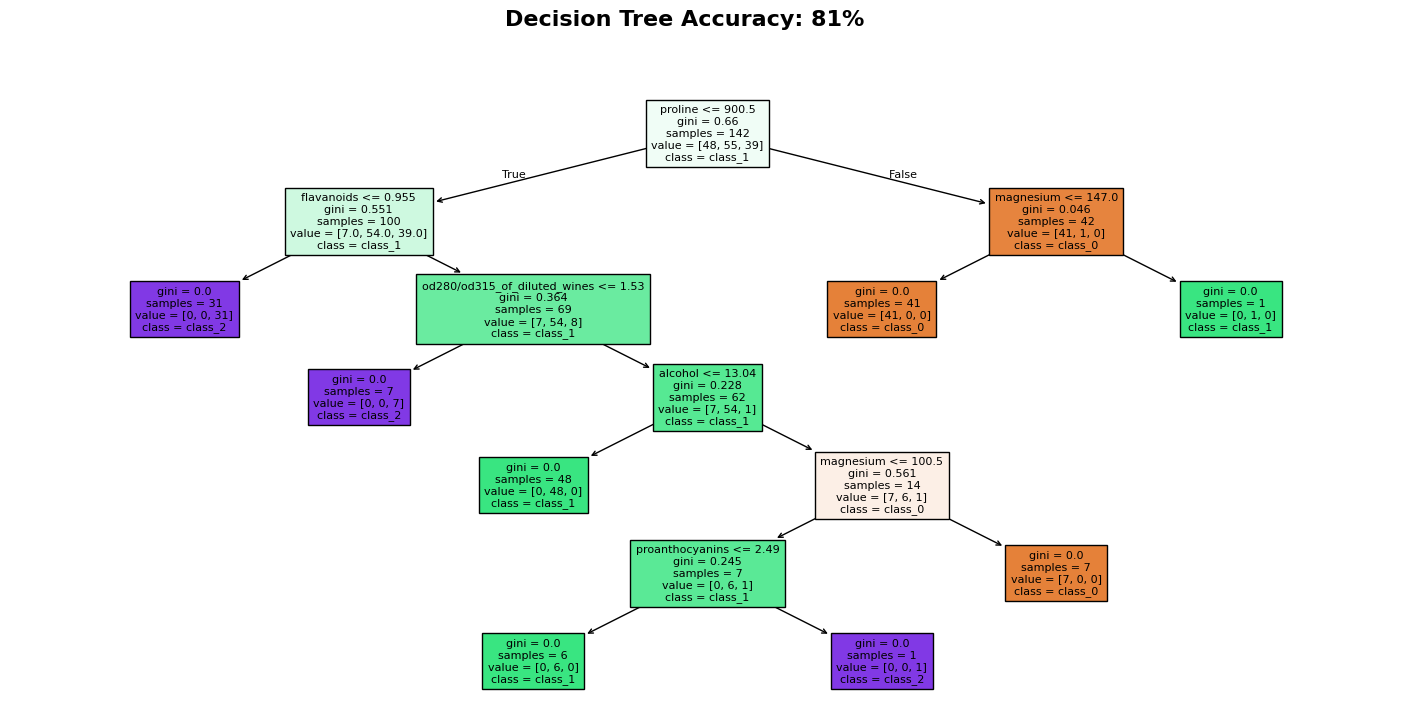

In [1]:
# import necessary functions from sklearn
from sklearn.datasets import load_wine
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Load the wine dataset
wine = load_wine()
X_train, X_test, y_train, y_test = train_test_split(wine.data, wine.target, test_size=0.2, random_state=30)

# Create a decision tree classifier
clf_dt = DecisionTreeClassifier()
clf_dt.fit(X_train, y_train)

# Make predictions
predictions = clf_dt.predict(X_test)

# Evaluate accuracy
accuracy = accuracy_score(y_test, predictions)

# Plot the decision tree
plt.figure(figsize=(18, 8))
plt.suptitle(f"Decision Tree Accuracy: {int(round(accuracy, 2)*100)}%", fontsize=16, fontweight='bold')
plot_tree(clf_dt, feature_names=wine.feature_names, class_names=wine.target_names, filled=True, fontsize=8)
plt.savefig('./Images/decision_tree_example.png')

### Decision Tree Example

![Decision Tree Example](./Images/decision_tree_example.png)

There is a lot to unpack here! 

Each box is a decision point AND the class if deciding ends there. Let's go through what each line of the box means:
- **Decision**: This is the decision we will use to split from this box. The "machine learning" of this model is in calculating what decision "best splits" the data. 
- **gini**: This is the calculation that decided on the best decision to make at this point of the tree. 'gini' is short for Gini Impurity, which is describing how often randomly choosing something from this box would incorrectly classify an item. Our best decision is the lowest gini (lowest chance to incorrectly classify an item).
- **samples**: How many samples we have at this decision point. In the first block, we have all samples. In the second level of blocks, we have 100 (left) and 42 (right). This tells us the first decision split the data into 100 samples and 42 samples. 
- **value**: This is how many sample values belong to each class. Looking at the second level of blocks, of the 100 samples in the left block we have 7 in class_0, 54 in class_1, and 39 in class_2. The right block has 41 in class_0, 1 in class_1, and 0 in class_2. So our first decision split off most of the class_0 data!
- **class**: This is the classification if the tree stopped at that block. This is always the class in the node with the most values. 

You'll also notice the accuracy of the model was included in the title. Methods to improve the Decision Tree accuracy will be presented later. 

### Pros and Cons of Decision Trees

Pros:
- **Handles complex relationships well** - The model makes very few assumptions about the predictive variables and can create many decisions to handle complex relationships.
- **Easy to interpret and/or visualize** - Decision points are easy to interpret and explain to non-experts. The flow of how to make a decision is easy to visualize. 
- **Computationally fast** - The gini calculation is computationally easy, making model training fast compared to other classification methods. 

Cons: 
- **Prone to overfitting data** - Since the tree can make so many decisions, it will make very specific decisions that may not generalize. For example, look at the right block of the second row in our example. This decision removes 1 class_1 value from the set. There were likely many decisions that could have done this, and it is unclear if this specific decision will generalize to more data. 
- **Sensitive to training data** - Hidden in the code for this example was a train-test split. This means splitting the data to use some of it to train the model, then the rest of it to test the accuracy of the trained model. Decision trees may dramatically change based on what data is used to be trained. Since the train-test split is a **random** split of the data, this may make the decision points change each time you run it. 

## Random Forest

In the pros and cons of decision trees, we talked about how they are prone to overfitting the data and sensitive to the training data. So instead of taking a single decision tree, a random forest creates many decision trees that vote on what should be each decision point. Models that use a bunch of other models are called Ensemble Models. 

### Code for Example

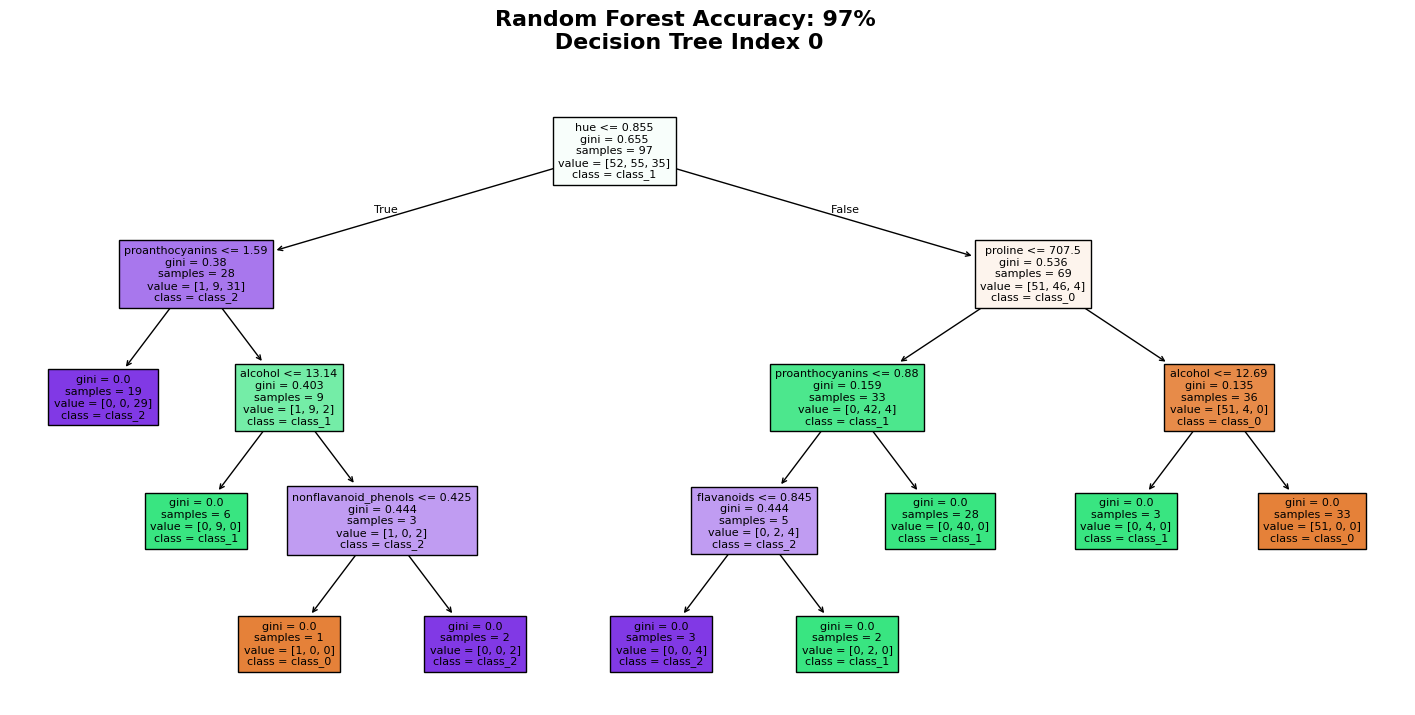

In [2]:
# import necessary functions from sklearn
from sklearn.datasets import load_wine
from sklearn.tree import plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Load the wine dataset
wine = load_wine()
X_train, X_test, y_train, y_test = train_test_split(wine.data, wine.target, test_size=0.2, random_state=30)

# Create a decision tree classifier
clf_rf = RandomForestClassifier()
clf_rf.fit(X_train, y_train)

# Make predictions
predictions = clf_rf.predict(X_test)

# Evaluate accuracy
accuracy = accuracy_score(y_test, predictions)

# Plot a decision tree
chosen_decision_tree_index = 0
plt.figure(figsize=(18, 8))
plt.suptitle(f"Random Forest Accuracy: {int(round(accuracy, 2)*100)}%\n Decision Tree Index {chosen_decision_tree_index}", fontsize=16, fontweight='bold')
plot_tree(clf_rf.estimators_[chosen_decision_tree_index], feature_names=wine.feature_names, class_names=wine.target_names, filled=True, fontsize=8)
plt.savefig('./Images/random_forest_decision_tree_example.png')

### Random Forest Example

Since Random Forest is an ensemble method, there is no one decision tree to display! Instead, you can extract decision trees being used to "vote". Otherwise, you just have to rely on evaluation measures like accuracy. 

![Random Forest Example](./Images/random_forest_decision_tree_example.png)

### Pros and Cons of Random Forest

Pros:
- **Handles complex relationships well** - The model makes very few assumptions about the predictive variables and can create many decisions to handle complex relationships.
- **Computationally fast** - Since each decision tree is computationally fast, the combination of many fast decision trees is still relatively fast. 
- **Resistant to overfitting** - Since many models are voting, the random forest is resistant to any individual tree influencing the final classification. 
- **More accurate that a single decision tree** - By collecting many decision trees to vote, the model avoids overfitting and so better generalizes to new data. This improves accuracy and other evlauation measures.

Cons: 
- **Difficult to interpret and/or visualize** - Since the random forest uses votting, there is no easy way to visualize the decisions. You can visualize individual decision trees but would have trouble visualizing *all* decision trees to understand how they are voting for each decision point. 

## Support Vector Machine

Support Vector Machines (SVMs) are known as *discriminative classifiers* as they attempt to find a way to divide classes with a "line". In 2 dimensions, this would be a single line splitting the plane in half and assigning classes to each side. In 3 dimensions, this would be a plane.

To figure out this best splitting line, we can think about lines with margins (so we have some room for error) that split the data. The line with the largest margin is then our best splitting line. Let's visualize this with an example.

### Code Needed for Example

In [27]:
def plot_svc_decision_function(model, ax=None, plot_support=True):
    """Plot the decision function for a 2D SVC"""
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    # create grid to evaluate model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)
    
    # plot decision boundary and margins
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])
    
    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

### SVM Example

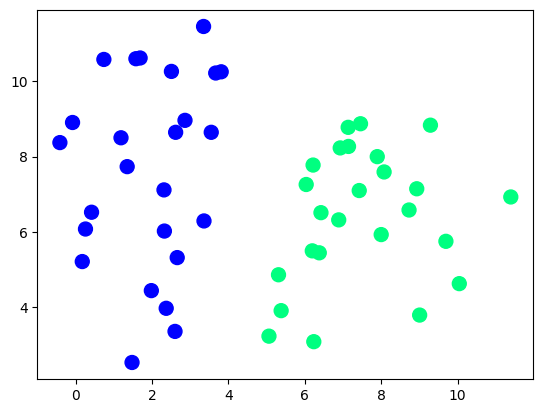

In [ ]:
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt

X, y = make_blobs(n_samples=50, centers=2, random_state=20, cluster_std=1.7)
plt.scatter(X[:, 0], X[:, 1], c=y, s=100, cmap='winter')

We can see the two sets of classes are clearly separated, so let's see what the SVM says is the line that best separates the two classes.

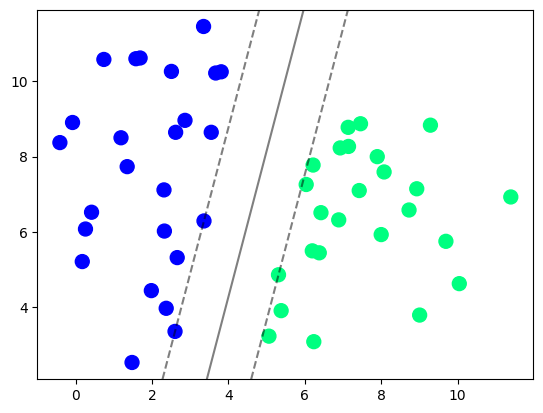

In [29]:
from sklearn.svm import SVC 
svc_model = SVC(kernel='linear', C=1E10)
svc_model.fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=100, cmap='winter')
plot_svc_decision_function(svc_model)

Awesome! But what happens if the data isn't so cleanly separated? 

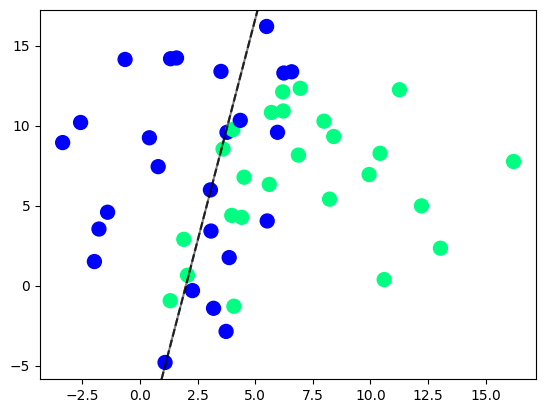

In [31]:
X_mixed, y_mixed = make_blobs(n_samples=50, centers=2, random_state=20, cluster_std=4)
plt.scatter(X_mixed[:, 0], X_mixed[:, 1], c=y_mixed, s=100, cmap='winter')

svc_model_mixed_data = SVC(kernel='linear', C=1E10)
svc_model_mixed_data.fit(X_mixed, y_mixed)

plot_svc_decision_function(svc_model_mixed_data)

We can see the margin is extremely small - invisible based on the scale of the image. We would say this data is *not* separable. This gives us one of the cons of SVMs: they work best with separable data. 

But is that the end of the story? Not quite. We can project our data into higher dimensions to create a linear separation there, then return that linear separation back into our lower dimension. We can visualize the result below. 

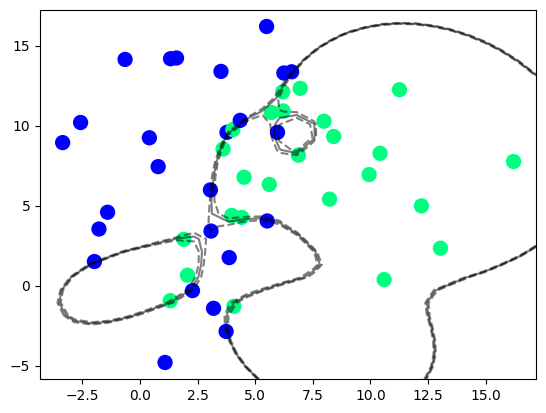

In [33]:
X_mixed, y_mixed = make_blobs(n_samples=50, centers=2, random_state=20, cluster_std=4)
plt.scatter(X_mixed[:, 0], X_mixed[:, 1], c=y_mixed, s=100, cmap='winter')

svc_model_mixed_data = SVC(kernel='rbf', C=1E6) # Radial Basis Function 
svc_model_mixed_data.fit(X_mixed, y_mixed)

plot_svc_decision_function(svc_model_mixed_data)

Lines in higher dimensions turn into curves in lower dimensions, letting us better separate our data with curves. 

We will not cover the mathematics behind how this model works as it requires Linear Algebra. 

### Pros and Cons of SVMs

Pros:
- **Low memory needs** - The model creates a few "support vectors" (hence the name) that are used to draw the separation line. These support vectors take up very little space. 
- **Fast Predictions** - Once the model is trained, predictions can be made quickly. 
- **Handles high-dimensional data** - If you look back at the examples, you'll notice the important points are those near the boundary. This lets the model work well with high-dimensional data.

Cons: 
- **Poorly scales with data size** - While SVM can handle high-dimensional data (many predictors to a response variable), it becomes computationally expensive as you add more data points. 
- **Reliant on choice of kernel and softening parameter** - We saw that for the non-separable example we changed the kernel to "rbf" (Radial Basis Function). This is one of many options. Sci-kit Learn comes with "linear", "poly", "rbf", "sigmoid", and "precomputed". Since the model can be computationally expensive to train, needing to test multiple kernel options and softening parameter C compounds the computational needs to train the model. 
- **Difficult to work with multiple classes** - SVM was designed for binary classification. While it can be extended to multiple classes, it is not well-suited for the task. 

## Logistic Regression

Recall that a *regression* model predicts a continuous variable. So what happens if that continuous variable is a probability of a class occuring? By modeling the probability of an event occuring and then setting a cutoff probability, we can classify based on the predicted probability. This is the essence to a logistic regression model. This normally works in binary classification.

### Code for Example

In [43]:
import numpy as np
import math
import matplotlib.pyplot as plt

# We will use sympy to solve for the x-value associated with our cutoff probability in order to graph it
from sympy import symbols, Eq, solve

def draw_logit_regression(cutoff):
    x = np.linspace(-5, 5, 30)
    logistic_y = ( math.e**x ) / (1 + math.e**x)

    fig, ax = plt.subplots(1, 1)
    ax.plot(x, logistic_y)

    # initalize empty sets to classify our x-values into
    classified_as_0 = []
    classified_as_1 = []

    # We'll define x_c as our variable since we are already using x as our set of x-values
    x_c = symbols('x_c')
    cutoff_equation = Eq(cutoff, ( math.e**x_c ) / (1 + math.e**x_c))
    x_value_for_cutoff = solve(cutoff_equation, x_c)[0]

    for x_value in x:
        if ( ( math.e**x_value ) / (1 + math.e**x_value) ) >= cutoff:
            classified_as_1.append(x_value)
        else:
            classified_as_0.append(x_value)

    plt.axvline(x=x_value_for_cutoff, color='g', linestyle='--')
    ax.plot(x, logistic_y, color='b')
    ax.scatter(classified_as_0, np.full((len(classified_as_0), 1), 0), color='r')
    ax.scatter(classified_as_1, np.full((len(classified_as_1), 1), 1), color='r')

### Example Graph

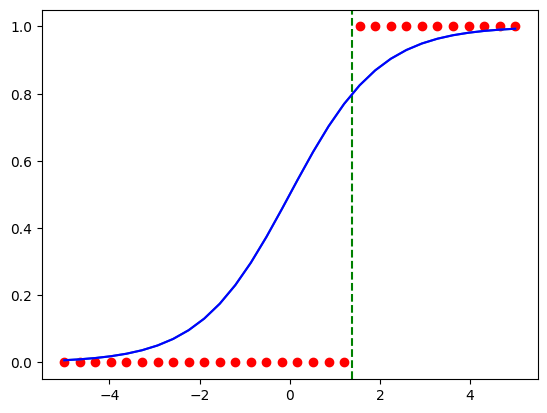

In [44]:
draw_logit_regression(cutoff=0.8)

In this example, the sigmoid (s-shaped) curve is the function that takes some x-value and provides the probability of x being class_1. Notice in the function definition we defined a cutoff probability. Any x-values with less than that probability is classified as class_0 (red dots sent to 0) while the rest is class_1 (red dots sent to 1). 

### Pros and Cons of Logistic Regression

Pros: 
- **Easy to interpret and visualize** - Since the classification decision is a simple probability comparison, the model is easy to interpret and visualize. 
- **Computationally fast** - As a linear model, it is computationally inexpensive on large data sets. 

Cons:
- **Many assumptions in background** - We will cover these assumptions in later Data Science courses, but there are a few hidden assumptions required to make a predictive logistic regression model. For our purposes, think of logistic regressions as best fitting simple relationships between predictive variables and a response class. 
- **Overfits with high-dimensional data** - Unlikely SVMs, Logistic Regressions do not handle high-dimensional (many predictors) data well and tends to overfit on this data. 